# Notebook 04 — Final Model Comparison & Summary

This presentation notebook **does not retrain** the module models. It loads the tables, predictions and pipelines saved
by notebooks 00–03 (run those first) and summarises them.

Scores from different modules are **never compared with each other**: forecast error (£), fraud precision/recall and
silhouette scores measure completely different things.

## Step 1 — Load saved results

Every expected file is checked; a missing file stops the notebook with its name instead of inventing a value.

In [1]:
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from forecast_features import recursive_daily_forecast
from fraud_features import add_fraud_features

FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"
PRED_DIR = PROJECT_ROOT / "outputs" / "predictions"
MODEL_DIR = PROJECT_ROOT / "models"

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (10, 5), "axes.titlesize": 13, "axes.labelsize": 11})
MAIN_COLOR = "#4C72B0"
ACCENT_COLOR = "#DD8452"
FRAUD_COLOR = "#C44E52"

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"04_{name}.png", dpi=120, bbox_inches="tight")

EXPECTED_FILES = {
    "data_overview": TABLE_DIR / "00_data_overview.csv",
    "retail_clean": PROJECT_ROOT / "data" / "processed" / "online_retail_clean.csv.gz",
    "fraud_raw": PROJECT_ROOT / "data" / "raw" / "Fraud_Data.csv",
    "forecast_metrics": TABLE_DIR / "01_forecast_metrics.csv",
    "forecast_full": TABLE_DIR / "01_forecast_full_metrics.csv",
    "forecast_predictions": PRED_DIR / "01_forecast_test_predictions.csv",
    "forecast_model": MODEL_DIR / "01_forecast_selected.joblib",
    "anomaly_comparison": TABLE_DIR / "02_anomaly_method_comparison.csv",
    "anomaly_full": TABLE_DIR / "02_anomaly_full_metrics.csv",
    "anomaly_flag_rates": TABLE_DIR / "02_anomaly_flag_rates.csv",
    "anomaly_burst": TABLE_DIR / "02_anomaly_train_burst_detection.csv",
    "anomaly_scores": PRED_DIR / "02_anomaly_test_scores.csv",
    "anomaly_model": MODEL_DIR / "02_isolation_forest_pipeline.joblib",
    "cluster_profiles": TABLE_DIR / "03_cluster_profiles.csv",
    "segment_value": TABLE_DIR / "03_segment_value.csv",
    "k_evaluation": TABLE_DIR / "03_k_evaluation.csv",
    "future_value": TABLE_DIR / "03_future_value_metrics.csv",
    "customer_segments": PRED_DIR / "03_customer_segments.csv",
    "segmentation_model": MODEL_DIR / "03_segmentation_pipeline.joblib",
}
missing = [f"{key}: {path.relative_to(PROJECT_ROOT)}" for key, path in EXPECTED_FILES.items() if not path.exists()]
if missing:
    raise FileNotFoundError("Run notebooks 00-03 first. Missing outputs:\n  " + "\n  ".join(missing))
print(f"All {len(EXPECTED_FILES)} expected files found.")

data_overview = pd.read_csv(EXPECTED_FILES["data_overview"]).set_index("dataset")
forecast_metrics = pd.read_csv(EXPECTED_FILES["forecast_metrics"], index_col="model")
forecast_full = pd.read_csv(EXPECTED_FILES["forecast_full"], index_col="model")
forecast_predictions = pd.read_csv(EXPECTED_FILES["forecast_predictions"], parse_dates=["week_ending"])
forecast_bundle = joblib.load(EXPECTED_FILES["forecast_model"])
anomaly_comparison = pd.read_csv(EXPECTED_FILES["anomaly_comparison"], index_col="method")
anomaly_full = pd.read_csv(EXPECTED_FILES["anomaly_full"], index_col="method")
flag_rates = pd.read_csv(EXPECTED_FILES["anomaly_flag_rates"])
burst_detection = pd.read_csv(EXPECTED_FILES["anomaly_burst"])
anomaly_scores = pd.read_csv(EXPECTED_FILES["anomaly_scores"])
anomaly_bundle = joblib.load(EXPECTED_FILES["anomaly_model"])
cluster_profiles = pd.read_csv(EXPECTED_FILES["cluster_profiles"], index_col="segment")
segment_value = pd.read_csv(EXPECTED_FILES["segment_value"], index_col="segment")
k_evaluation = pd.read_csv(EXPECTED_FILES["k_evaluation"], index_col="K")
future_value = pd.read_csv(EXPECTED_FILES["future_value"], index_col="model")
customer_segments = pd.read_csv(EXPECTED_FILES["customer_segments"])
segmentation_bundle = joblib.load(EXPECTED_FILES["segmentation_model"])
print("Loaded all module outputs.")

All 19 expected files found.


Loaded all module outputs.


## Step 2 — Project overview

In [2]:
data_overview

,raw_rows,clean_rows,period,customers,label,modules
dataset,,,,,,
Online Retail II,1067371,1021272,2009-12-01 to 2011-12-09,5875,none (unsupervised),"A, C"
E-commerce Fraud Data,151112,151112,2015-01-01 to 2015-12-16,151112,class (fraud rate 9.36%),B


| Module | Dataset | Business question | Selected approach | Why |
|---|---|---|---|---|
| **A. Revenue forecasting** | UCI Online Retail II | How much net revenue next week? | Combination of seasonal naive + daily XGBoost | Lowest test error on every metric; ML adds value once a full year of history exists |
| **B. Anomaly & risk detection** | E-commerce Fraud Data | Which purchases should be reviewed? | Isolation Forest (unsupervised), 5 % review rate | Best ranking of real fraud on unseen customers, without needing labels |
| **C. Segmentation & value** | UCI Online Retail II | Which customer groups exist and what are they worth? | RFM (log) + K-Means, K = 4 | Elbow and local silhouette peak; four clearly interpretable segments |

**Why two datasets?** No single public e-commerce dataset combines real seasonal sales, real repeat customers *and* a
confirmed fraud label. Version 1 of the project used one dataset whose revenue was pure noise and which had no fraud
label; version 2 uses the best available dataset for each problem.

## Step 3 — Forecasting results

In [3]:
forecast_metrics[["test_MAE", "test_RMSE", "test_R2", "test_MAPE_%", "backtest_MAE"]].round(1)

,test_MAE,test_RMSE,test_R2,test_MAPE_%,backtest_MAE
model,,,,,
Combination (seasonal naive + daily XGBoost),31966.2,41784.9,0.7,14.4,33443.1
Seasonal naive (last year),33707.3,44281.2,0.6,15.6,28268.1
XGBoost (daily→weekly),35195.6,43326.6,0.6,15.3,44927.4
XGBoost (weekly),37109.1,49511.3,0.5,16.2,44544.1
Random Forest (daily→weekly),40203.7,50356.3,0.5,17.1,44002.8
Random Forest (weekly),41557.8,50142.6,0.5,17.5,44251.7
Linear Regression (weekly),44972.9,55536.6,0.4,19.2,36985.3
Naive (last week),44981.9,56518.7,0.4,19.5,42662.9
Training mean,71648.0,96037.3,-0.8,26.2,48526.7


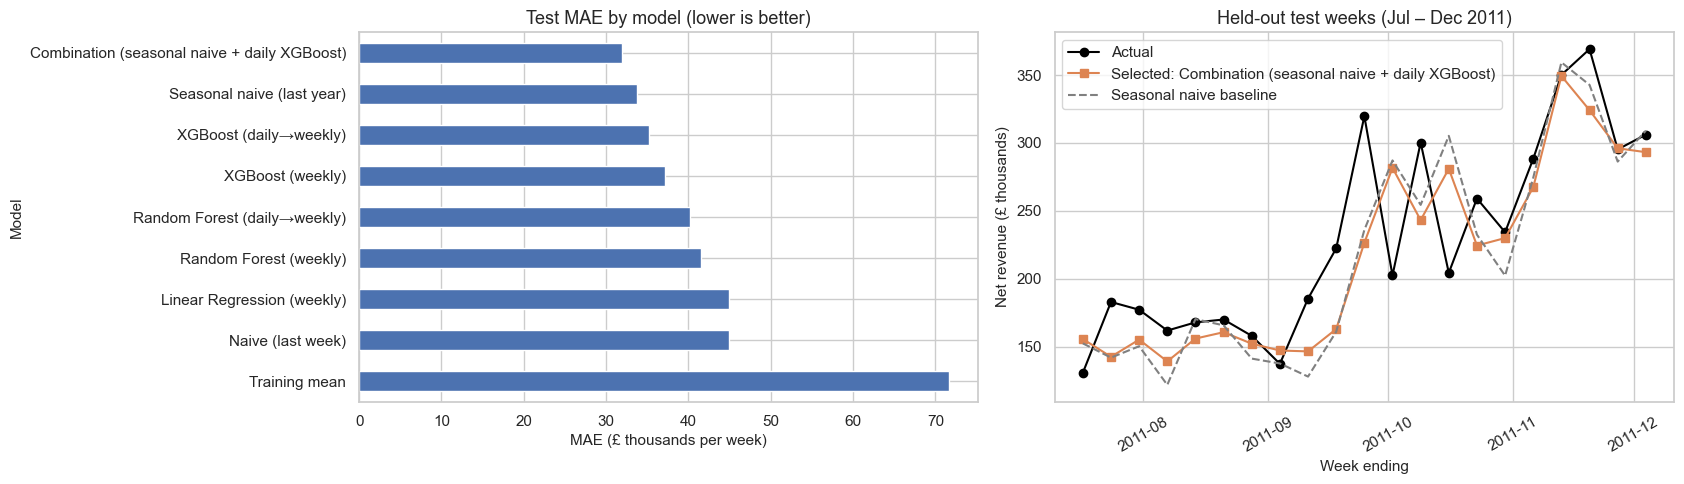

Selected vs Seasonal naive (last year)  : MAE £31,966 vs £33,707 (5.2% lower)
Selected vs XGBoost (daily→weekly)      : MAE £31,966 vs £35,196 (9.2% lower)
Selected vs XGBoost (weekly)            : MAE £31,966 vs £37,109 (13.9% lower)
Selected vs Training mean               : MAE £31,966 vs £71,648 (55.4% lower)


In [4]:
selected_forecaster = forecast_bundle["selected_model_name"]
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
forecast_metrics["test_MAE"].div(1e3).sort_values().plot.barh(ax=axes[0], color=MAIN_COLOR)
axes[0].invert_yaxis()
axes[0].set_title("Test MAE by model (lower is better)")
axes[0].set_xlabel("MAE (£ thousands per week)")
axes[0].set_ylabel("Model")
axes[1].plot(forecast_predictions["week_ending"], forecast_predictions["actual_revenue"] / 1e3, marker="o", color="black", label="Actual")
axes[1].plot(forecast_predictions["week_ending"], forecast_predictions["selected_prediction"] / 1e3, marker="s", color=ACCENT_COLOR,
             label=f"Selected: {selected_forecaster}")
axes[1].plot(forecast_predictions["week_ending"], forecast_predictions["pred_Seasonal naive (last year)"] / 1e3, linestyle="--",
             color="gray", label="Seasonal naive baseline")
axes[1].set_title("Held-out test weeks (Jul – Dec 2011)")
axes[1].set_xlabel("Week ending")
axes[1].set_ylabel("Net revenue (£ thousands)")
axes[1].tick_params(axis="x", rotation=30)
axes[1].legend()
save_fig("forecast_summary")
plt.show()

selected_mae = forecast_metrics.loc[selected_forecaster, "test_MAE"]
for other in ["Seasonal naive (last year)", "XGBoost (daily→weekly)", "XGBoost (weekly)", "Training mean"]:
    print(f"Selected vs {other:28s}: MAE £{selected_mae:,.0f} vs £{forecast_metrics.loc[other, 'test_MAE']:,.0f} "
          f"({1 - selected_mae / forecast_metrics.loc[other, 'test_MAE']:.1%} lower)")

**Interpretation:** the selected combination misses actual weekly revenue by about £32k on average (≈ 14 % MAPE)
during the hardest part of the year — the autumn peak. It is 5 % better than the strong seasonal-naive baseline and
55 % better than assuming an average week. The backtest showed the honest caveat: before one full year of history
existed, the ML part was worse than simply repeating last year.

## Step 4 — Anomaly & risk detection results

In [5]:
anomaly_comparison.round(3)

,uses_labels,ROC_AUC,PR_AUC,flag_rate,precision,recall,lift
method,,,,,,,
Isolation Forest,False,0.638,0.120,0.050,0.216,0.235,4.707
LOF,False,0.561,0.081,0.050,0.142,0.154,3.090
Rule-based,False,0.632,0.104,0.063,0.230,0.315,5.005
XGBoost (supervised),True,0.632,0.107,0.050,0.206,0.224,4.491


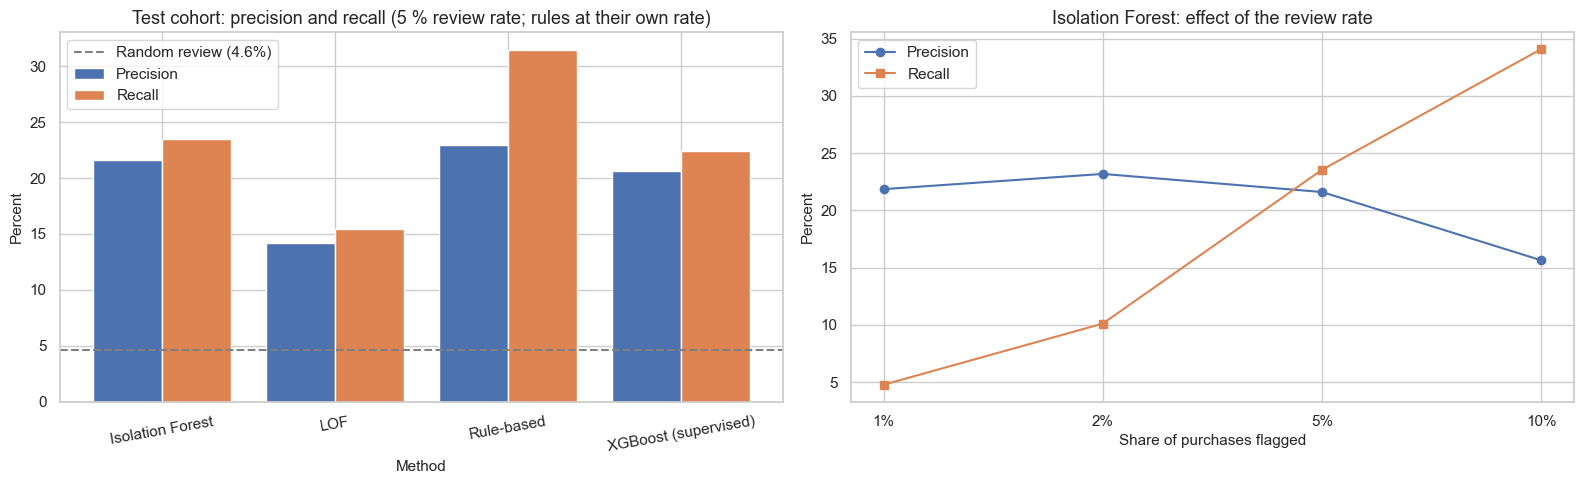

Unsupervised detection inside the training cohort (labels never used for fitting):
 flag_rate  precision  recall  share_of_flags_that_are_instant_purchases
      0.02      0.806   0.153                                      0.797
      0.05      0.890   0.422                                      0.885
      0.10      0.697   0.660                                      0.628


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
x = np.arange(len(anomaly_comparison))
axes[0].bar(x - 0.2, anomaly_comparison["precision"] * 100, width=0.4, color=MAIN_COLOR, label="Precision")
axes[0].bar(x + 0.2, anomaly_comparison["recall"] * 100, width=0.4, color=ACCENT_COLOR, label="Recall")
test_fraud_rate = anomaly_bundle["test_fraud_rate"]
axes[0].axhline(test_fraud_rate * 100, color="gray", linestyle="--", label=f"Random review ({test_fraud_rate:.1%})")
axes[0].set_xticks(x, anomaly_comparison.index, rotation=10)
axes[0].set_title("Test cohort: precision and recall (5 % review rate; rules at their own rate)")
axes[0].set_xlabel("Method")
axes[0].set_ylabel("Percent")
axes[0].legend()
axes[1].plot([f"{r:.0%}" for r in flag_rates["flag_rate"]], flag_rates["precision"] * 100, marker="o", color=MAIN_COLOR, label="Precision")
axes[1].plot([f"{r:.0%}" for r in flag_rates["flag_rate"]], flag_rates["recall"] * 100, marker="s", color=ACCENT_COLOR, label="Recall")
axes[1].set_title("Isolation Forest: effect of the review rate")
axes[1].set_xlabel("Share of purchases flagged")
axes[1].set_ylabel("Percent")
axes[1].legend()
save_fig("anomaly_summary")
plt.show()
print("Unsupervised detection inside the training cohort (labels never used for fitting):")
print(burst_detection.round(3).to_string(index=False))

**Interpretation:** on customers it had never seen (July–August signups), Isolation Forest's review queue is about
**22 % fraud versus 4.6 % at random** (lift ≈ 4.7×) and catches about a quarter of the fraud, without ever using a label.
Inside the training cohort it ranked the January bot burst at the top (top 5 % ≈ 89 % fraud). A supervised XGBoost
trained on past labels did *not* do better, because January's bot fraud no longer appears later. The main detectable
signal after January is **device reuse**, which a simple rule captures equally well.

## Step 5 — Customer segmentation results

In [7]:
selected_k = int(k_evaluation.index[k_evaluation["selected"]][0])
print(f"K = {selected_k}, silhouette = {k_evaluation.loc[selected_k, 'silhouette']:.3f}")
cluster_profiles[["customers", "share_of_customers", "recency_median", "frequency_median", "monetary_median"]].round(3)

K = 4, silhouette = 0.365


,customers,share_of_customers,recency_median,frequency_median,monetary_median
segment,,,,,
Champions,1107,0.190,15.0,13.0,5032.22
At-risk regulars,1477,0.253,158.0,5.0,1529.82
Recent low-spend,1220,0.209,23.0,3.0,702.18
Lapsed one-time buyers,2028,0.348,399.5,1.0,280.82


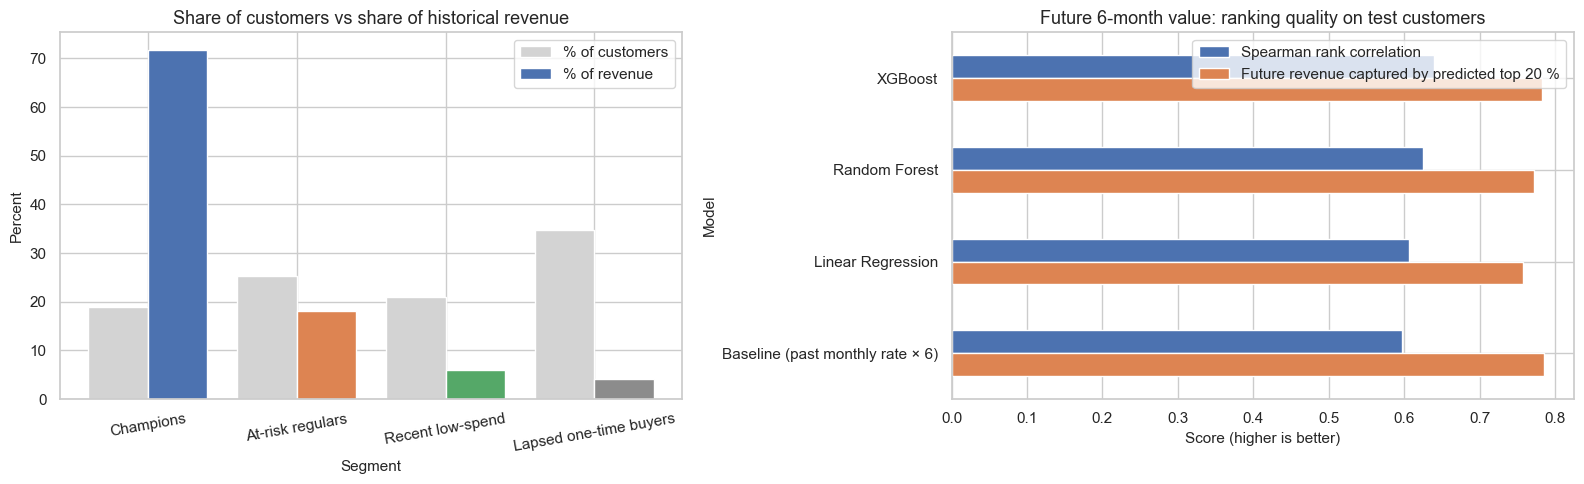

,MAE,Spearman,top20_capture,RMSE,MedAE,R2,R2_log
model,,,,,,,
XGBoost,751.770,0.640,0.782,4967.528,93.616,0.427,0.402
Random Forest,704.792,0.625,0.772,4699.232,95.499,0.487,0.382
Linear Regression,943.333,0.607,0.757,6977.962,97.759,-0.131,0.361
Baseline (past monthly rate × 6),732.458,0.597,0.786,2488.932,308.863,0.856,-0.401


In [8]:
segment_colors = dict(zip(cluster_profiles.index, ["#4C72B0", "#DD8452", "#55A868", "#8C8C8C"]))
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
width = 0.4
x = np.arange(len(segment_value))
axes[0].bar(x - width / 2, segment_value["share_of_customers"] * 100, width, color="lightgray", label="% of customers")
axes[0].bar(x + width / 2, segment_value["share_of_revenue"] * 100, width, color=[segment_colors[s] for s in segment_value.index], label="% of revenue")
axes[0].set_xticks(x, segment_value.index, rotation=10)
axes[0].set_title("Share of customers vs share of historical revenue")
axes[0].set_xlabel("Segment")
axes[0].set_ylabel("Percent")
axes[0].legend()
future_value[["Spearman", "top20_capture"]].plot.barh(ax=axes[1], color=[MAIN_COLOR, ACCENT_COLOR])
axes[1].invert_yaxis()
axes[1].set_title("Future 6-month value: ranking quality on test customers")
axes[1].set_xlabel("Score (higher is better)")
axes[1].set_ylabel("Model")
axes[1].legend(["Spearman rank correlation", "Future revenue captured by predicted top 20 %"])
save_fig("segmentation_summary")
plt.show()
future_value.round(3)

**Interpretation:** Champions (19 % of customers) produced 72 % of historical revenue; together with At-risk regulars
they account for 90 %. For *future* value, every approach — including a simple past-spending baseline — puts about
77–79 % of next-6-month revenue into its predicted top 20 % of customers; ML improves overall ranking slightly
(Spearman 0.64 vs 0.60) but not top-20 % targeting.

## Step 6 — Prediction / demo section

### 6a. Forecasting: the next four weeks after the data

The daily XGBoost is run **recursively** (each predicted week becomes history for the next) and combined 50/50 with
the actual revenue of the same week one year earlier — the same rule as the selected model. The model was trained
only on the training weeks, so this is an illustration, not a production forecast.

In [9]:
retail = pd.read_csv(EXPECTED_FILES["retail_clean"], parse_dates=["InvoiceDate"], dtype={"Invoice": str, "StockCode": str})
daily = retail.set_index("InvoiceDate")["revenue"].resample("D").sum()
weekly = daily.resample("W-SUN").sum()
last_complete_week = weekly.index[-2]
daily_history = daily.loc[:last_complete_week]

ml_part = recursive_daily_forecast(forecast_bundle["xgb_daily_model"], daily_history, n_weeks=4)
same_week_last_year = weekly.reindex(ml_part.index - pd.Timedelta(weeks=52)).values
future_forecast = pd.DataFrame({
    "week_ending": ml_part.index.date,
    "daily_xgboost_part": ml_part.values.round(0),
    "same_week_last_year": same_week_last_year.round(0),
    "combined_forecast": ((ml_part.values + same_week_last_year) / 2).round(0),
})
print("Last complete week in the data:", last_complete_week.date(),
      f"| partial actual for the week ending {ml_part.index[0].date()} (Mon–Fri only): £{weekly.iloc[-1]:,.0f}")
future_forecast

Last complete week in the data: 2011-12-04 | partial actual for the week ending 2011-12-11 (Mon–Fri only): £310,943


,week_ending,daily_xgboost_part,same_week_last_year,combined_forecast
0,2011-12-11,297092.0,296070.0,296581.0
1,2011-12-18,212830.0,202184.0,207507.0
2,2011-12-25,146327.0,82624.0,114475.0
3,2012-01-01,17731.0,0.0,8866.0


The combined forecast follows the pre-Christmas level and then the Christmas closure, because both components know
the calendar. **A real check is possible for the first week:** the data contains Monday–Friday of the week ending
11 Dec 2011, and those five days alone (≈ £311k) already exceed the forecast (≈ £297k) — consistent with the
under-prediction bias seen in notebook 01, where 2011 ran ahead of 2010. Given the test MAE of ≈ £32k, any week could reasonably differ by tens of thousands of pounds.

### 6b. Anomaly detection: score real purchases with the saved pipeline

Features are rebuilt from the raw file with the same function as notebook 02 (device / IP counts look only backwards),
then scored by the saved pipeline. The scores must match those saved by notebook 02.

In [10]:
fraud_features = add_fraud_features(pd.read_csv(EXPECTED_FILES["fraud_raw"], parse_dates=["signup_time", "purchase_time"]))
demo_users = list(anomaly_scores.nlargest(3, "iforest_score")["user_id"]) + list(anomaly_scores.nsmallest(3, "iforest_score")["user_id"])
demo = fraud_features.set_index("user_id").loc[demo_users]
demo_scores = -anomaly_bundle["pipeline"].score_samples(demo[anomaly_bundle["features"]])
demo_result = demo[["purchase_value", "age", "prior_purchases_same_device", "prior_purchases_same_ip", "log_seconds_to_purchase", "class"]].copy()
demo_result["anomaly_score"] = demo_scores
demo_result["flag_for_review"] = (demo_scores >= anomaly_bundle["threshold_from_training_cohort"]).astype(int)
saved = anomaly_scores.set_index("user_id").loc[demo_users, "iforest_score"]
print("Scores match notebook 02:", bool(np.allclose(demo_scores, saved, atol=1e-4)))
print(f"Review threshold (95th percentile of training-cohort scores): {anomaly_bundle['threshold_from_training_cohort']:.4f}")
demo_result.round(3)

Scores match notebook 02: True
Review threshold (95th percentile of training-cohort scores): 0.6555


,purchase_value,age,prior_purchases_same_device,prior_purchases_same_ip,log_seconds_to_purchase,class,anomaly_score,flag_for_review
user_id,,,,,,,,
243984,77,29,14,0,5.668,0,0.673,1
134576,100,52,1,0,6.829,0,0.662,1
67350,60,19,14,0,6.972,0,0.655,0
361265,33,31,0,0,6.764,0,0.365,0
205998,33,31,0,0,6.853,0,0.366,0
368779,35,31,0,0,6.790,0,0.367,0


Note: the threshold is the 95th percentile of the **training** cohort's scores. Because the training cohort contains the
January bots (very high scores), this threshold is stricter than the 5 % test-cohort quantile used for evaluation —
in deployment the threshold should be re-set from recent purchases.

### 6c. Customer segmentation: assign customers with the saved pipeline

In [11]:
demo_customers = customer_segments.groupby("segment").head(1)["Customer ID"].tolist()
demo_rfm = customer_segments.set_index("Customer ID").loc[demo_customers, segmentation_bundle["rfm_columns"]]
demo_rfm["cluster"] = segmentation_bundle["pipeline"].predict(demo_rfm[segmentation_bundle["rfm_columns"]])
demo_rfm["segment"] = demo_rfm["cluster"].map(segmentation_bundle["segment_names"])
saved_segments = customer_segments.set_index("Customer ID").loc[demo_customers, "segment"]
print("Segments match notebook 03:", bool((demo_rfm["segment"] == saved_segments).all()))
demo_rfm

Segments match notebook 03: True


,Recency,Frequency,Monetary,cluster,segment
Customer ID,,,,,
12346,325,3,169.36,1,Lapsed one-time buyers
12347,2,8,4921.53,2,Champions
12348,75,5,1658.40,0,At-risk regulars
12349,18,3,3654.54,3,Recent low-spend


## Step 7 — Final model summary table

Built from the loaded output files — no value is typed by hand.

In [12]:
iforest = anomaly_comparison.loc["Isolation Forest"]
champions = segment_value.loc["Champions"]
best_future = future_value["Spearman"].idxmax()
summary_table = pd.DataFrame([
    {"Module": "Revenue forecasting", "Dataset": "Online Retail II",
     "Selected approach": selected_forecaster,
     "Evaluation method": "Time-based test (last 21 weeks) + 3-window backtest: MAE / RMSE / R² / MAPE",
     "Main result": f"MAE £{selected_mae:,.0f} ({forecast_metrics.loc[selected_forecaster, 'test_MAPE_%']:.1f} % MAPE, "
                    f"R² {forecast_metrics.loc[selected_forecaster, 'test_R2']:.2f}); "
                    f"{1 - selected_mae / forecast_metrics.loc['Seasonal naive (last year)', 'test_MAE']:.1%} better than seasonal naive",
     "Limitation": "Only one previous season; ML worse than baseline before a full year of history"},
    {"Module": "Anomaly & risk detection", "Dataset": "E-commerce Fraud Data",
     "Selected approach": f"Isolation Forest, {anomaly_bundle['review_rate']:.0%} review rate",
     "Evaluation method": "Unseen signup cohort with fraud labels: ROC-AUC, PR-AUC, precision / recall / lift",
     "Main result": f"ROC-AUC {iforest['ROC_AUC']:.2f}; precision {iforest['precision']:.1%}, recall {iforest['recall']:.1%}, "
                    f"lift {iforest['lift']:.1f}×",
     "Limitation": "Most flags are still legitimate; fraud patterns change over time"},
    {"Module": "Customer segmentation & value", "Dataset": "Online Retail II",
     "Selected approach": f"RFM (log) + K-Means, K = {selected_k}",
     "Evaluation method": "Elbow, silhouette, profiles; future value on an 18 + 6-month time split",
     "Main result": f"Silhouette {k_evaluation.loc[selected_k, 'silhouette']:.2f}; Champions = {champions['share_of_customers']:.0%} of "
                    f"customers, {champions['share_of_revenue']:.0%} of revenue; best future-value Spearman "
                    f"{future_value.loc[best_future, 'Spearman']:.2f} ({best_future})",
     "Limitation": "Historical value ≠ lifetime value; 6-month future window only"},
]).set_index("Module")
summary_table.to_csv(TABLE_DIR / "04_final_model_summary.csv")
with pd.option_context("display.max_colwidth", None):
    display(summary_table)

,Dataset,Selected approach,Evaluation method,Main result,Limitation
Module,,,,,
Revenue forecasting,Online Retail II,Combination (seasonal naive + daily XGBoost),Time-based test (last 21 weeks) + 3-window backtest: MAE / RMSE / R² / MAPE,"MAE £31,966 (14.4 % MAPE, R² 0.65); 5.2% better than seasonal naive",Only one previous season; ML worse than baseline before a full year of history
Anomaly & risk detection,E-commerce Fraud Data,"Isolation Forest, 5% review rate","Unseen signup cohort with fraud labels: ROC-AUC, PR-AUC, precision / recall / lift","ROC-AUC 0.64; precision 21.6%, recall 23.5%, lift 4.7×",Most flags are still legitimate; fraud patterns change over time
Customer segmentation & value,Online Retail II,"RFM (log) + K-Means, K = 4","Elbow, silhouette, profiles; future value on an 18 + 6-month time split","Silhouette 0.36; Champions = 19% of customers, 72% of revenue; best future-value Spearman 0.64 (XGBoost)",Historical value ≠ lifetime value; 6-month future window only


## Step 7b — Complete metrics for every model

Every model trained in notebooks 01–03, with the full metric set computed there. Models are compared **only within
their own module** (a £ error cannot be compared with a fraud precision). Within each table, **★** marks the best value
in each column and `overall_rank` (1 = best) averages each model's ranks on the module's key metrics.

In [13]:
def mark_best(table, higher_is_better, lower_is_better, fmt="{:.3f}"):
    """Format a metric table as text and put a ★ next to the best value in each listed column."""
    shown = table.copy().astype(object)
    for column in list(higher_is_better) + list(lower_is_better):
        values = table[column].dropna()
        best = values.idxmax() if column in higher_is_better else values.idxmin()
        shown[column] = [fmt.format(v) + (" ★" if i == best else "") for i, v in table[column].items()]
    return shown

print("A. REVENUE FORECASTING — regression metrics on the 21 held-out test weeks")
forecast_view = forecast_full[["test_MAE", "test_RMSE", "test_MedAE", "test_R2", "test_MAPE_%", "test_accuracy_%",
                               "test_within_10%", "test_within_20%", "test_bias", "train_MAE", "train_R2",
                               "backtest_MAE", "backtest_RMSE", "overall_rank"]]
with pd.option_context("display.max_columns", None, "display.width", 250):
    display(mark_best(forecast_view,
                      ["test_R2", "test_accuracy_%", "test_within_10%", "test_within_20%"],
                      ["test_MAE", "test_RMSE", "test_MedAE", "test_MAPE_%", "backtest_MAE", "backtest_RMSE"],
                      fmt="{:,.2f}"))

A. REVENUE FORECASTING — regression metrics on the 21 held-out test weeks


,test_MAE,test_RMSE,test_MedAE,test_R2,test_MAPE_%,test_accuracy_%,test_within_10%,test_within_20%,test_bias,train_MAE,train_R2,backtest_MAE,backtest_RMSE,overall_rank
model,,,,,,,,,,,,,,
Combination (seasonal naive + daily XGBoost),"31,966.24 ★","41,784.91 ★","22,729.58 ★",0.65 ★,14.44 ★,85.56 ★,0.43,0.71 ★,13716.3427,16427.4905,0.8303,"33,443.09","42,266.47",1
Seasonal naive (last year),"33,707.28","44,281.19","26,649.74",0.61,15.61,84.39,0.38,0.67,12540.5238,28076.8144,0.4941,"28,268.06 ★","35,360.44 ★",2
XGBoost (daily→weekly),"35,195.56","43,326.61","28,094.43",0.63,15.30,84.70,0.43,0.67,14892.1616,7090.2823,0.9714,"44,927.38","63,889.23",3
XGBoost (weekly),"37,109.07","49,511.34","24,500.19",0.51,16.15,83.85,0.48 ★,0.62,8781.8535,2528.8477,0.9959,"44,544.06","57,399.97",4
Random Forest (daily→weekly),"40,203.67","50,356.30","29,077.93",0.49,17.13,82.87,0.33,0.67,15797.0059,10533.1137,0.9247,"44,002.84","60,921.82",5
Random Forest (weekly),"41,557.84","50,142.59","36,737.21",0.50,17.55,82.45,0.24,0.67,20195.7016,17089.1737,0.7299,"44,251.70","58,260.25",6
Linear Regression (weekly),"44,972.94","55,536.62","36,258.26",0.39,19.21,80.79,0.29,0.52,12513.9746,25129.3094,0.6011,"36,985.28","46,512.58",7
Naive (last week),"44,981.91","56,518.72","37,260.47",0.36,19.52,80.48,0.33,0.57,6582.7605,42422.1846,-0.1337,"42,662.94","51,753.15",8
Training mean,"71,648.02","96,037.34","39,483.46",-0.84,26.20,73.80,0.29,0.43,64824.2827,43648.0354,-0.1686,"48,526.69","55,600.61",9


In [14]:
print("B. ANOMALY & RISK DETECTION — classification metrics on the unseen Jul–Aug signup cohort")
anomaly_view = anomaly_full[["flag_rate", "TP", "FP", "FN", "TN", "accuracy", "balanced_accuracy", "precision",
                             "recall", "specificity", "F1", "MCC", "ROC_AUC", "PR_AUC", "overall_rank"]]
methods_only = anomaly_view.drop("No flags (baseline)")
with pd.option_context("display.max_columns", None, "display.width", 250):
    display(pd.concat([mark_best(methods_only, ["balanced_accuracy", "precision", "recall", "F1", "MCC", "ROC_AUC", "PR_AUC"], []),
                       anomaly_view.loc[["No flags (baseline)"]].round(3).astype(object)]))
print("Note: the 'No flags' baseline has the highest plain accuracy while catching no fraud — accuracy is not a useful "
      "metric at a 4.6 % fraud rate.")

B. ANOMALY & RISK DETECTION — classification metrics on the unseen Jul–Aug signup cohort


,flag_rate,TP,FP,FN,TN,accuracy,balanced_accuracy,precision,recall,specificity,F1,MCC,ROC_AUC,PR_AUC,overall_rank
method,,,,,,,,,,,,,,,
Isolation Forest,0.05,326,1183,1059,27610,0.9257,0.597,0.216,0.235,0.9589,0.225,0.186,0.638 ★,0.120 ★,1.0
Rule-based,0.0629,436,1462,949,27331,0.9201,0.632 ★,0.230 ★,0.315 ★,0.9492,0.266 ★,0.228 ★,0.632,0.104,1.0
XGBoost (supervised),0.05,311,1198,1074,27595,0.9247,0.592,0.206,0.225,0.9584,0.215,0.176,0.632,0.107,3.0
LOF,0.05,214,1295,1171,27498,0.9183,0.555,0.142,0.154,0.955,0.148,0.105,0.561,0.081,4.0
No flags (baseline),0.0,0,0,1385,28793,0.954,0.5,0.0,0.0,1.0,0.0,0.0,0.5,0.046,NaN


Note: the 'No flags' baseline has the highest plain accuracy while catching no fraud — accuracy is not a useful metric at a 4.6 % fraud rate.


In [15]:
print("C1. CUSTOMER SEGMENTATION — K-Means cluster-quality metrics for every K tried")
k_view = k_evaluation[["inertia", "silhouette", "davies_bouldin", "calinski_harabasz", "selected"]]
display(mark_best(k_view, ["silhouette", "calinski_harabasz"], ["davies_bouldin"]))

print("C2. FUTURE CUSTOMER VALUE — regression and ranking metrics on test customers")
value_view = future_value[["MAE", "RMSE", "MedAE", "R2", "R2_log", "Spearman", "top20_capture"]].copy()
value_ranks = pd.DataFrame({"MAE": value_view["MAE"].rank(), "RMSE": value_view["RMSE"].rank(),
                            "R2_log": value_view["R2_log"].rank(ascending=False),
                            "Spearman": value_view["Spearman"].rank(ascending=False),
                            "top20_capture": value_view["top20_capture"].rank(ascending=False)})
value_view["overall_rank"] = value_ranks.mean(axis=1).rank(method="min").astype(int)
value_view = value_view.sort_values("overall_rank")
display(mark_best(value_view, ["R2", "R2_log", "Spearman", "top20_capture"], ["MAE", "RMSE", "MedAE"]))

C1. CUSTOMER SEGMENTATION — K-Means cluster-quality metrics for every K tried


,inertia,silhouette,davies_bouldin,calinski_harabasz,selected
K,,,,,
2,8544.5583,0.439 ★,0.874 ★,6107.628 ★,False
3,6332.7632,0.347,1.037,5137.614,False
4,4929.7299,0.365,0.942,4952.069,True
5,4110.4108,0.341,0.955,4743.943,False
6,3565.8471,0.333,0.964,4551.951,False
7,3195.5214,0.302,0.979,4344.814,False
8,2906.1616,0.303,0.977,4176.926,False


C2. FUTURE CUSTOMER VALUE — regression and ranking metrics on test customers


,MAE,RMSE,MedAE,R2,R2_log,Spearman,top20_capture,overall_rank
model,,,,,,,,
XGBoost,751.770,4967.528,93.616 ★,0.427,0.402 ★,0.640 ★,0.782,1
Random Forest,704.792 ★,4699.232,95.499,0.487,0.382,0.625,0.772,1
Baseline (past monthly rate × 6),732.458,2488.932 ★,308.863,0.856 ★,-0.401,0.597,0.786 ★,3
Linear Regression,943.333,6977.962,97.759,-0.131,0.361,0.607,0.757,4


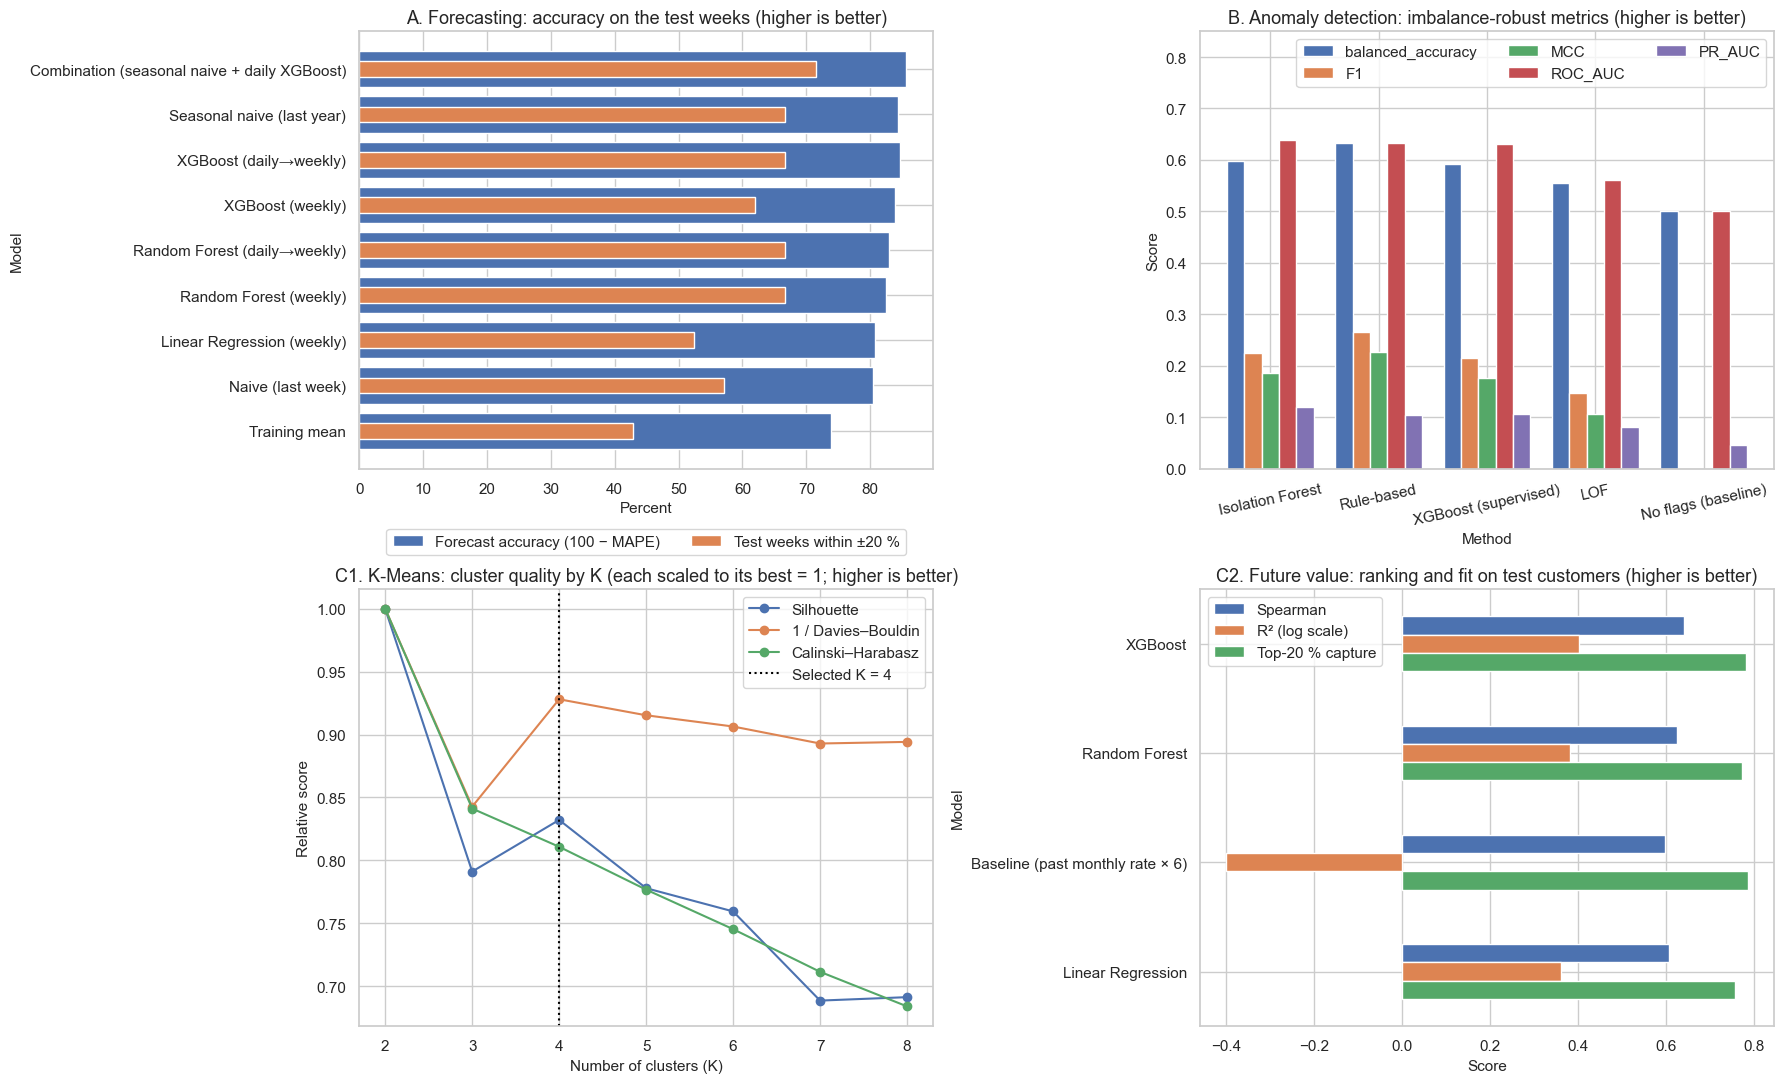

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(18, 11))

order = forecast_full.sort_values("test_MAE").index
axes[0, 0].barh(order, forecast_full.loc[order, "test_accuracy_%"], color=MAIN_COLOR, label="Forecast accuracy (100 − MAPE)")
axes[0, 0].barh(order, forecast_full.loc[order, "test_within_20%"] * 100, color=ACCENT_COLOR, height=0.35,
                label="Test weeks within ±20 %")
axes[0, 0].invert_yaxis()
axes[0, 0].set_title("A. Forecasting: accuracy on the test weeks (higher is better)")
axes[0, 0].set_xlabel("Percent")
axes[0, 0].set_ylabel("Model")
axes[0, 0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)

anomaly_plot = anomaly_full[["balanced_accuracy", "F1", "MCC", "ROC_AUC", "PR_AUC"]]
anomaly_plot.plot.bar(ax=axes[0, 1], width=0.8)
axes[0, 1].set_ylim(0, 0.85)
axes[0, 1].legend(loc="upper right", ncol=3)
axes[0, 1].set_title("B. Anomaly detection: imbalance-robust metrics (higher is better)")
axes[0, 1].set_xlabel("Method")
axes[0, 1].set_ylabel("Score")
axes[0, 1].tick_params(axis="x", rotation=12)

k_scaled = k_evaluation[["silhouette", "davies_bouldin", "calinski_harabasz"]].copy()
k_scaled["davies_bouldin"] = 1 / k_scaled["davies_bouldin"]
k_scaled = k_scaled / k_scaled.max()
k_scaled.columns = ["Silhouette", "1 / Davies–Bouldin", "Calinski–Harabasz"]
k_scaled.plot(ax=axes[1, 0], marker="o")
axes[1, 0].axvline(selected_k, color="black", linestyle=":", label=f"Selected K = {selected_k}")
axes[1, 0].set_title("C1. K-Means: cluster quality by K (each scaled to its best = 1; higher is better)")
axes[1, 0].set_xlabel("Number of clusters (K)")
axes[1, 0].set_ylabel("Relative score")
axes[1, 0].legend()

value_view[["Spearman", "R2_log", "top20_capture"]].plot.barh(ax=axes[1, 1])
axes[1, 1].invert_yaxis()
axes[1, 1].set_title("C2. Future value: ranking and fit on test customers (higher is better)")
axes[1, 1].set_xlabel("Score")
axes[1, 1].set_ylabel("Model")
axes[1, 1].legend(["Spearman", "R² (log scale)", "Top-20 % capture"])
save_fig("full_metric_comparison")
plt.show()

**Interpretation — which model wins on the full metric set:**

| Module | Best overall | Runner-up | What the extra metrics add |
|---|---|---|---|
| A. Forecasting | **Combination** (rank 1; accuracy 85.6 %, 71 % of weeks within ±20 %) | Seasonal naive (best backtest) | Train-vs-test gap reveals heavy overfitting in weekly / daily XGBoost |
| B. Anomaly detection | **Isolation Forest** (best ROC-AUC / PR-AUC) and **Rule-based** (best F1 / MCC), tied | Supervised XGBoost | Accuracy (~92–95 %) is useless here: the "flag nothing" baseline scores highest |
| C1. Segmentation | **K = 4** among K ≥ 3 (best silhouette and Davies–Bouldin) | K = 3 / K = 5 (close) | Calinski–Harabasz only favours K = 2 |
| C2. Future value | **XGBoost** for ranking (Spearman, log R²); **Random Forest** for MAE | Baseline for top-20 % capture and raw-£ R² | The baseline is accurate on large accounts but poor on typical customers (MedAE £309 vs ≈ £94) |

The model selected in each module stays the same: the extended metrics support the decisions already made in
notebooks 01–03.

## Step 8 — Final conclusion

**1. Which forecasting model performed best on the held-out period, and by how much?**
The **combination of seasonal naive and daily XGBoost**: test MAE ≈ £32.0k per week (≈ 14 % MAPE, R² ≈ 0.65), 5.2 %
lower than the seasonal-naive baseline (£33.7k), 9 % lower than daily XGBoost alone (£35.2k) and 55 % lower than the
training mean (£71.6k).

**2. What kinds of transactions were flagged as unusual?**
Purchases from **devices and IP addresses already used by other accounts**, especially in quick succession, and — in
January — purchases made within one second of signup (bots). On unseen customers about 22 % of flagged purchases were
fraud versus 4.6 % at random.

**3. What customer segments were identified?**
Champions (19 % of customers, 72 % of revenue), At-risk regulars (25 %, 18 %), Recent low-spend (21 %, 6 %) and
Lapsed one-time buyers (35 %, 4 %).

**4. How could the results help an e-commerce business?**
- Plan stock and staff for the September–November peak using a forecast that is accurate to about ±14 % per week.
- Review the ~5 % most unusual new-customer purchases — about 5× more likely to be fraud than a random check.
- Protect Champions, win back At-risk regulars, and grow Recent low-spend customers, rather than spending equally on everyone.

**5. Limitations and data that would improve the models**
- Forecasting: more years of history, promotion calendars and a growth adjustment.
- Anomaly detection: richer payment / address / device data and up-to-date fraud labels; the dataset's origin is undocumented.
- Segmentation & value: customer type (wholesale vs retail), longer horizons for true lifetime value, and the 22 % of
  sales without a customer ID.

### Measured findings vs assumptions

| Measured (from executed code) | Assumption / judgment |
|---|---|
| All forecast errors, backtest results, Ljung–Box p-values | The test period (autumn 2011) is representative of future peaks |
| Precision, recall, lift, ROC/PR-AUC against real fraud labels | A 5 % review capacity; fraud labels are correct |
| Silhouette, segment sizes, revenue shares, future-value Spearman | K = 4 is the most useful granularity; segment names are descriptive labels |

**Overall:** with suitable data, the three modules give measurable, honest results: a forecast that beats strong
baselines, an anomaly detector whose usefulness is proven against real fraud labels, and customer segments backed by
both historical and future spending.